# Python front end: parameter scans and ion phase space

## Pablo Requeijo

This notebook drives the hybrid PIC directly from Python through the `pic_prequeijo` module (pybind11, `python/bindings.cpp`). It runs exactly the same C++ code as the `pic_prequeijo` driver (the pytest suite checks they agree bit for bit), but two kinds of analysis become easy that the driver makes tedious:

1. **Parameter scans**: dozens of runs with different settings, without writing one `.txt` input file per run.
2. **Particle data**: the driver only saves grid moments, while `HybridSimulation.particles()` returns every macroparticle's position and velocity at any time.

## Setup

Build the project first (from `PIC/build`, configured with the repo venv): `cmake .. -DPython_EXECUTABLE=../../.venv/bin/python && cmake --build .`. This notebook needs no `results.h5`: every run happens here.

In [1]:
import sys

import numpy as np
import matplotlib.pyplot as plt

# Shared notebook helpers (python/) and the pybind11 module (build/).
sys.path[:0] = ["python", "build"]
import pic_analysis as pa
import pic_prequeijo as pic

pa.apply_style()

## 1. Dispersion relation from a wavenumber scan

`analysis_session_3.ipynb` checks one R and one L eigenmode at $k d_i = 1$, and sees the whole dispersion relation only through thermal noise. Here each eigenmode is run separately, for 12 wavenumbers on each branch, and its frequency is measured from the phase of its Fourier mode (`pa.mode_frequency`). It is compared with two references:

- the continuous cold-plasma relation $\omega^2 + k^2\omega - k^2 = 0$ (`pic.wave_frequency`), which the code approaches as $\Delta x \to 0$;
- the dispersion relation of the discrete scheme (`pic.discrete_wave_frequency`, derived in `TESTS.md`), $\omega^2 + (K^2 - \sigma)\,\omega - K^2 = 0$. Here $K = (2/\Delta x)\sin(k\Delta x/2)$ is the wavenumber the Yee curl sees, and $\sigma = 4\sin^2(k\Delta x/2)\,(1/6 + 1/(12\,\text{ppc}^2))$ is the fraction by which the linear shape (gather, then deposit) reduces the ion response.

Setup: cold protons (4 per cell) in $\vec B_0 = \hat x$, box $L = 8\pi\,d_i$, so mode $m$ has $k = m/4$ and $m = 1 \dots 12$ spans $k d_i = 0.25 \dots 3$. Each run lasts 3 wave periods, and the wave amplitude $10^{-3}$ keeps it linear. $dt = 0.005$ is below the whistler stability limit $n\,dx^2/2 = 0.019$ for $n_x = 128$.

In [2]:
BOX_LENGTH = 8 * np.pi
WAVE_AMPLITUDE = 1e-3
PERIODS_PER_RUN = 3
PARTICLES_PER_CELL = 4
SCAN_MODES = np.arange(1, 13)
BRANCHES = ("L", "R")


def measure_eigenmode(branch, mode, nx, dt):
    # Runs one cold eigenmode for PERIODS_PER_RUN periods and returns its
    # wavenumber, its measured frequency, and the relative error of that
    # frequency against the continuous and the discrete references.
    k = 2 * np.pi * mode / BOX_LENGTH
    exact = pic.wave_frequency(k, branch)
    discrete = pic.discrete_wave_frequency(k, BOX_LENGTH / nx, PARTICLES_PER_CELL, branch)
    steps = int(np.ceil(PERIODS_PER_RUN * 2 * np.pi / abs(exact) / dt))
    sim = pic.HybridSimulation(nx=nx, length=BOX_LENGTH, dt=dt, B=(1, 0, 0),
                               ppc=PARTICLES_PER_CELL, wave_mode=int(mode),
                               wave_amplitude=WAVE_AMPLITUDE, wave_branch=branch,
                               output_every=5)
    sim.run(steps)
    omega, _ = pa.mode_frequency(sim.history(), k)
    return k, omega, (omega - exact) / exact, (omega - discrete) / discrete


SCAN_NX, SCAN_DT = 128, 0.005
scan = {branch: np.array([measure_eigenmode(branch, mode, SCAN_NX, SCAN_DT)
                          for mode in SCAN_MODES])
        for branch in BRANCHES}
for branch in BRANCHES:
    k, omega, error, error_discrete = scan[branch].T
    print(f"{branch} branch: |error| vs continuous {np.abs(error).min():.1e} to "
          f"{np.abs(error).max():.1e}; vs discrete at most {np.abs(error_discrete).max():.1e}")

L branch: |error| vs continuous 7.4e-04 to 3.1e-03; vs discrete at most 3.6e-05
R branch: |error| vs continuous 9.3e-04 to 3.2e-02; vs discrete at most 1.7e-04


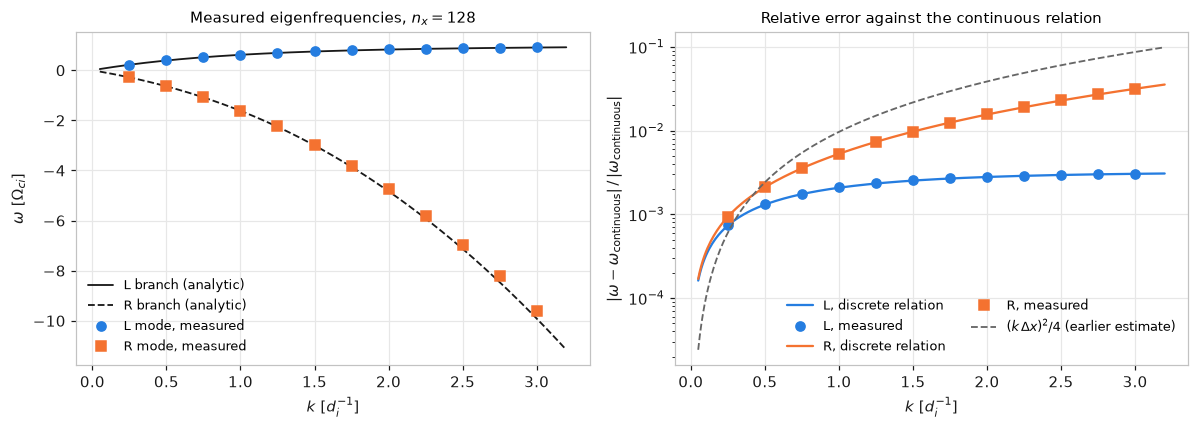

L branch: the discrete relation explains 98.7% to 99.8% of the error
R branch: the discrete relation explains 99.5% to 99.9% of the error


In [3]:
dx = BOX_LENGTH / SCAN_NX
k_dense = np.linspace(0.05, 3.2, 300)
markers = {"L": "o", "R": "s"}
colors = {"L": pa.L_BRANCH_COLOR, "R": pa.R_BRANCH_COLOR}

fig, (ax_w, ax_err) = plt.subplots(1, 2, figsize=(11, 4))
pa.plot_wave_branches(ax_w, k_dense)
for branch in BRANCHES:
    k, omega, error, _ = scan[branch].T
    ax_w.plot(k, omega, markers[branch], color=colors[branch], ms=6,
              label=f"{branch} mode, measured")
    # Error the discrete relation predicts against the continuous one.
    exact = pic.wave_frequency(k_dense, branch)
    predicted = pic.discrete_wave_frequency(k_dense, dx, PARTICLES_PER_CELL, branch) / exact - 1
    ax_err.plot(k_dense, np.abs(predicted), color=colors[branch], lw=1.5,
                label=f"{branch}, discrete relation")
    ax_err.plot(k, np.abs(error), markers[branch], color=colors[branch], ms=6,
                label=f"{branch}, measured")
ax_err.plot(k_dense, (k_dense * dx)**2 / 4, color=pa.ANALYTIC_COLOR, lw=1.2, ls="--",
            label=r"$(k\,\Delta x)^2/4$ (earlier estimate)")
ax_w.set(xlabel=r"$k\ [d_i^{-1}]$", ylabel=r"$\omega\ [\Omega_{ci}]$",
         title=r"Measured eigenfrequencies, $n_x = 128$")
ax_err.set(xlabel=r"$k\ [d_i^{-1}]$",
           ylabel=r"$|\omega - \omega_{\rm continuous}|\,/\,|\omega_{\rm continuous}|$",
           yscale="log", title="Relative error against the continuous relation")
ax_w.legend()
ax_err.legend(ncol=2)
plt.tight_layout()
plt.show()

# How much of the error the discrete relation explains, run by run.
for branch in BRANCHES:
    k, omega, error, error_discrete = scan[branch].T
    explained = 1 - np.abs(error_discrete / error)
    print(f"{branch} branch: the discrete relation explains {explained.min():.1%} "
          f"to {explained.max():.1%} of the error")

Both branches follow the analytic relation, from the Alfvénic regime ($|\omega| \approx k$ at small $k$) to the ion-cyclotron saturation of L ($\omega \to \Omega_{ci}$) and the quadratic whistler growth of R. The error against the continuous relation grows to 3 % on the R branch at $k d_i = 3$ ($k\,\Delta x = 0.59$, about 11 cells per wavelength), and the discrete relation predicts it point by point: the measured frequencies are not just close to the continuous ones, they are the frequencies of the discrete scheme.

The two discrete operators act differently:

- **Yee curl**: $k^2 \to K^2 = k^2\,(1 - (k\Delta x)^2/12 + \dots)$. It dominates the large-$k$ whistler, whose frequency grows like $K^2$.
- **Shape-function smoothing**: $\sigma \approx (k\Delta x)^2/6$ weakens the ion current against the Hall current and enters as $-\sigma\omega$, not through $k^2$. At small $k$, where $\omega \approx \pm k$, it shifts both branches by $+\sigma/2$, a relative error $\approx k\,\Delta x^2/12$ that is odd in $k$. That is why the error exceeds the earlier estimate $(k\,\Delta x)^2/4$ (dashed), which assumed every discretization error acts through $k^2$, below $k d_i = 1/3$.

The eigenmode tests of the Catch2 suite now compare with the discrete frequency instead of the continuous one (`TESTS.md`), with a tolerance about 17 times tighter.

### Convergence with the cell size

Both discrete operators are second order, so halving $\Delta x$ must divide the error against the continuous relation by 4, at every $k$, and the discrete relation must keep predicting it (thin lines). The time step is fixed at $dt = 0.0025$, stable for the finest mesh ($n_x = 256$, limit $0.0048$), and small enough that the second-order time error stays below the spatial one.

L, k = 0.25: error ratios when dx halves: 4.00, 3.99
L, k = 1: error ratios when dx halves: 3.98, 3.99
L, k = 3: error ratios when dx halves: 3.85, 3.98
R, k = 0.25: error ratios when dx halves: 4.00, 4.01
R, k = 1: error ratios when dx halves: 3.97, 3.99
R, k = 3: error ratios when dx halves: 3.83, 3.94


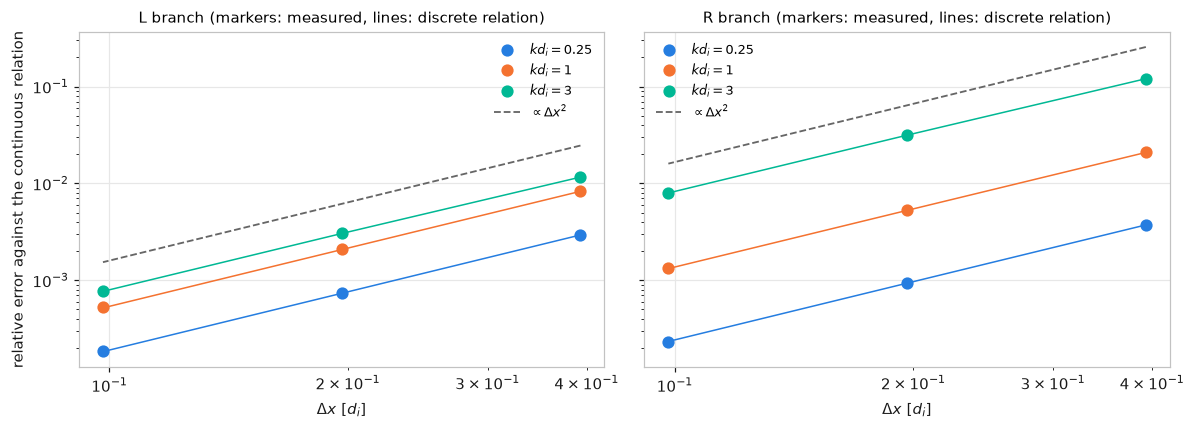

In [4]:
CONVERGENCE_NX = np.array([64, 128, 256])
CONVERGENCE_MODES = (1, 4, 12)
CONVERGENCE_DT = 0.0025

convergence = {(branch, mode): np.array([measure_eigenmode(branch, mode, nx, CONVERGENCE_DT)[2]
                                         for nx in CONVERGENCE_NX])
               for branch in BRANCHES for mode in CONVERGENCE_MODES}

dx_values = BOX_LENGTH / CONVERGENCE_NX
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, branch in zip(axes, BRANCHES):
    for slot, mode in enumerate(CONVERGENCE_MODES):
        k = 2 * np.pi * mode / BOX_LENGTH
        error = np.abs(convergence[(branch, mode)])
        discrete = np.array([pic.discrete_wave_frequency(k, dx, PARTICLES_PER_CELL, branch)
                             for dx in dx_values])
        predicted = np.abs(discrete / pic.wave_frequency(k, branch) - 1)
        ax.plot(dx_values, predicted, color=pa.SERIES_COLORS[slot], lw=1)
        ax.plot(dx_values, error, "o", color=pa.SERIES_COLORS[slot], ms=7,
                label=rf"$k d_i = {mode / 4:g}$")
        ratios = error[1:] / error[:-1]
        print(f"{branch}, k = {mode / 4:g}: error ratios when dx halves: "
              + ", ".join(f"{1 / r:.2f}" for r in ratios))
    # Slope-2 reference, shifted above the largest error so it does not hide it.
    top = max(np.abs(convergence[(branch, mode)])[-1] for mode in CONVERGENCE_MODES)
    ax.plot(dx_values, 2 * top * (dx_values / dx_values[-1])**2, color=pa.ANALYTIC_COLOR,
            lw=1.2, ls="--", label=r"$\propto \Delta x^2$")
    ax.set(xscale="log", yscale="log", xlabel=r"$\Delta x\ [d_i]$",
           title=f"{branch} branch (markers: measured, lines: discrete relation)")
    ax.legend()
axes[0].set_ylabel("relative error against the continuous relation")
plt.tight_layout()
plt.show()

Every curve is parallel to $\Delta x^2$: the error drops by a factor of 4 each time $\Delta x$ halves (printed ratios 3.8 to 4.0), at all three wavenumbers, and the measured points sit on the discrete relation at every resolution. The excess over $(k\,\Delta x)^2/4$ at small $k$ is the $-\sigma\omega$ term of the shape function, a second-order spatial error with a coefficient odd in $k$; it converges like the rest. What the discrete relation leaves (0.1 to 1.3 % of the error in the scan above) shrinks with longer runs and is the beat with the other branch, excited because each ion is loaded with the continuous eigenmode velocity (see `TESTS.md`).

## 2. Ion phase space in an ion acoustic wave

The driver saves only the grid moments $n$ and $\vec u$; here the macroparticles themselves are inspected. Setup as `examples/density_sine.txt`, but with the initial density passed as a NumPy array instead of a profile file: cold protons, $T_e = 1$, $L = 20\pi$, $n(x, 0) = 1 + \varepsilon\cos kx$ with $\varepsilon = 0.01$ and $k = 2\pi/L = 0.1$.

**Linear solution.** The density bump launches a standing ion acoustic wave, $n = 1 + \varepsilon\cos kx\cos\omega t$ with $\omega = k\sqrt{T_e}$. Continuity, $\partial_t n + \partial_x(n u_x) = 0$, gives to first order in $\varepsilon$

$$u_x(x, t) = \varepsilon\sqrt{T_e}\,\sin kx\,\sin\omega t.$$

The ions are cold, so each one should move with the local bulk velocity: in the $(x, v_x)$ plane they must lie on this curve. Its amplitude is $\varepsilon\sqrt{T_e} = 0.01$, reached at $t = T/4$ and $3T/4$; at $t = T/2$ the ions are momentarily at rest.

t =  15.70 (T/4): max |v_x - u_x| = 8.49e-05 = 0.8% of the amplitude, max |v_y|, |v_z| = 0.0e+00


t =  31.40 (T/2): max |v_x - u_x| = 1.82e-04 = 1.8% of the amplitude, max |v_y|, |v_z| = 0.0e+00
t =  47.10 (3T/4): max |v_x - u_x| = 2.50e-04 = 2.5% of the amplitude, max |v_y|, |v_z| = 0.0e+00


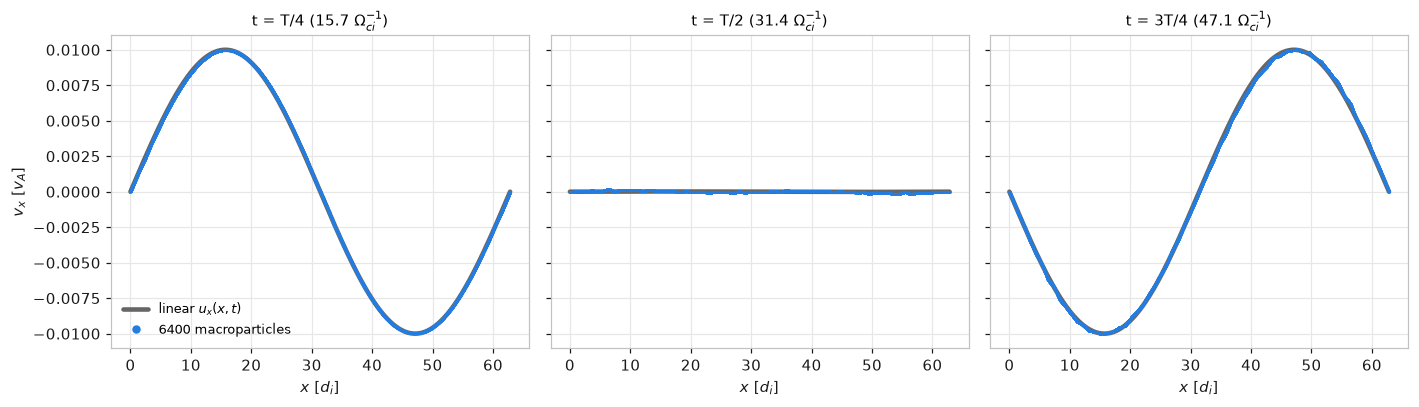

In [5]:
DENSITY_EPSILON = 0.01
ELECTRON_TEMPERATURE = 1.0
ACOUSTIC_NX, ACOUSTIC_LENGTH, ACOUSTIC_DT = 64, 20 * np.pi, 0.05

k = 2 * np.pi / ACOUSTIC_LENGTH
x_nodes = np.arange(ACOUSTIC_NX) * ACOUSTIC_LENGTH / ACOUSTIC_NX
sim = pic.HybridSimulation(nx=ACOUSTIC_NX, length=ACOUSTIC_LENGTH, dt=ACOUSTIC_DT,
                           B=(1, 0, 0), Te=ELECTRON_TEMPERATURE, ppc=100,
                           density=1 + DENSITY_EPSILON * np.cos(k * x_nodes))
omega = k * np.sqrt(ELECTRON_TEMPERATURE)
period = 2 * np.pi / omega
u_amplitude = DENSITY_EPSILON * np.sqrt(ELECTRON_TEMPERATURE)
x_dense = np.linspace(0, ACOUSTIC_LENGTH, 400)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, fraction, name in zip(axes, (0.25, 0.5, 0.75), ("T/4", "T/2", "3T/4")):
    sim.run(int(round(fraction * period / ACOUSTIC_DT)) - sim.step)
    particles = sim.particles()
    vx = particles["v"][:, 0]
    u_particles = u_amplitude * np.sin(k * particles["x"]) * np.sin(omega * sim.time)
    deviation = np.abs(vx - u_particles).max()
    print(f"t = {sim.time:6.2f} ({name}): max |v_x - u_x| = {deviation:.2e} "
          f"= {deviation / u_amplitude:.1%} of the amplitude, "
          f"max |v_y|, |v_z| = {np.abs(particles['v'][:, 1:]).max():.1e}")
    ax.plot(x_dense, u_amplitude * np.sin(k * x_dense) * np.sin(omega * sim.time),
            color=pa.ANALYTIC_COLOR, lw=3, label=r"linear $u_x(x, t)$")
    ax.plot(particles["x"], vx, ".", ms=1.5, color=pa.SERIES_COLORS[0],
            label=f"{len(vx)} macroparticles")
    ax.set(xlabel=r"$x\ [d_i]$", title=f"t = {name} ({sim.time:.1f} $\\Omega_{{ci}}^{{-1}}$)")
axes[0].set_ylabel(r"$v_x\ [v_A]$")
axes[0].legend(loc="lower left", markerscale=6)
plt.tight_layout()
plt.show()

The macroparticles collapse onto the linear solution: a cold population is a single curve in phase space, and that curve oscillates as the standing wave, sloshing ions towards the density troughs and back. The largest deviation grows from 0.8 % to 2.5 % of the wave amplitude over three quarters of a period. That is of the same order as the terms the linear solution neglects (relative order $\varepsilon = 1\,\%$) and as the slow phase drift of the measured frequency ($\omega = 0.0999$ against $0.1$, see `README.md`); this notebook does not separate the two. $v_y$ and $v_z$ stay exactly zero, since in this longitudinal wave along $\vec B_0$ nothing pushes the ions across the field.